# Titanic - Random Forest & Bagging
**Dataset:** Titanic (seaborn)
**Task:** binary classification
**Covers:** single decision tree vs `RandomForestClassifier` (with OOB score) vs `BaggingClassifier` (decision tree and logistic regression base models).

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [2]:
titanic = sns.load_dataset("titanic")

features = ["pclass", "sex", "fare", "embarked", "age"]
target = ["survived"]

# handle missing data
# Pick the train/test rows first, so the imputers learn their fill values from training rows only
# (fitting them on the full dataset would leak test-set statistics into training)
train_idx, test_idx = train_test_split(titanic.index, test_size=0.3, random_state=42)

imp_median = SimpleImputer(strategy="median").fit(titanic.loc[train_idx, ["age"]])
titanic[["age"]] = imp_median.transform(titanic[["age"]])

imp_freq = SimpleImputer(strategy="most_frequent").fit(titanic.loc[train_idx, ["embarked"]])
titanic[["embarked"]] = imp_freq.transform(titanic[["embarked"]])

# encode
le = LabelEncoder()

titanic["sex"] = le.fit_transform(titanic["sex"])
titanic["embarked"] = le.fit_transform(titanic["embarked"])

X = titanic[features]
y = titanic["survived"]

# Train Test Split
# same rows that were chosen before imputation
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

In [3]:
# Decision Tree
model = DecisionTreeClassifier(max_depth=4, random_state=42)

model.fit(X_train, y_train)

y_pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)

print("Training accuracy: ", accuracy_score(y_train, y_pred_train)*100, "%")
print("Testing accuracy: ", accuracy_score(y_test, y_pred_test)*100, "%")
# compare train vs test accuracy to check for overfitting

Training accuracy:  84.75120385232745 %
Testing accuracy:  82.46268656716418 %


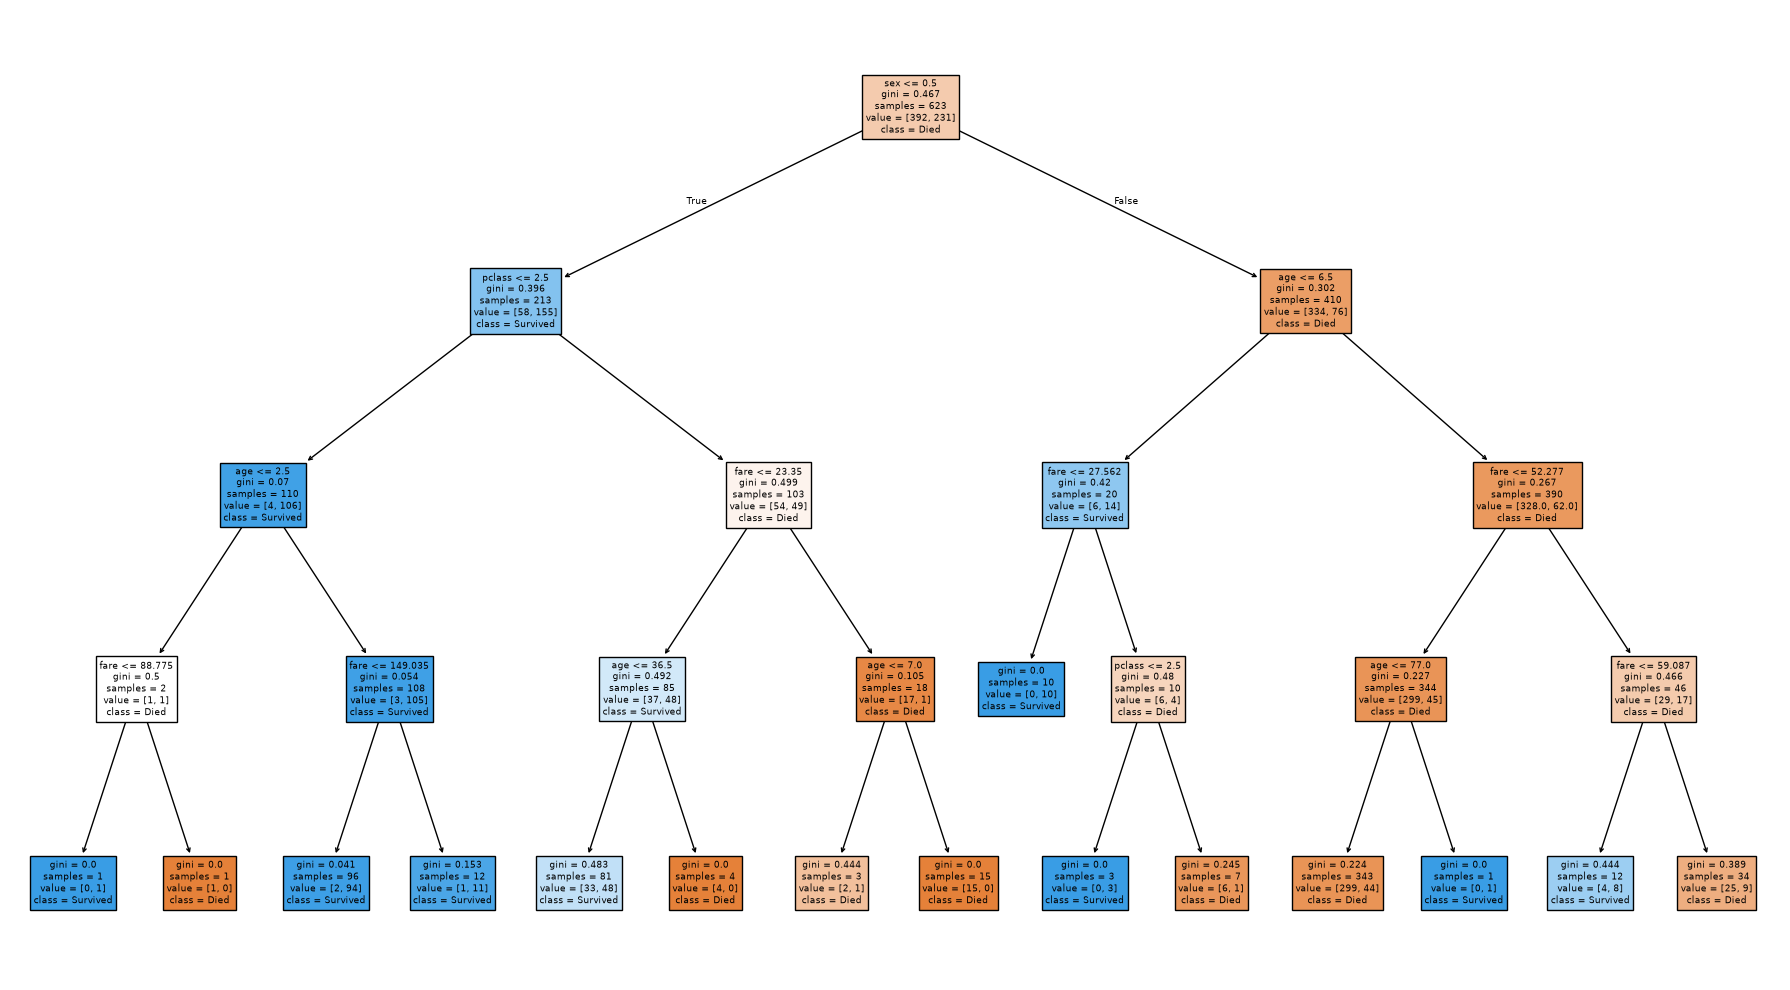

In [4]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 10))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Died", "Survived"],
    filled=True
)

plt.tight_layout()

## Random forest
Many decorrelated trees (bootstrap samples + random feature subsets). The **out-of-bag (OOB)** score is a free validation estimate computed on the rows each tree did not see.

In [5]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=501,
    oob_score=True,
    max_depth=4,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

print("OOB score: ", rf.oob_score_ * 100, "%")
print("testing accuracy: ", accuracy_score(y_test, y_pred) * 100, "%")


OOB score:  82.18298555377207 %
testing accuracy:  81.71641791044776 %


## Bagging
Bootstrap aggregating with a full decision tree, and then with logistic regression as the base model.

In [6]:
# Bagging Classifier

from sklearn.ensemble import BaggingClassifier

base_model = DecisionTreeClassifier()

bagging = BaggingClassifier(
    base_model,
    n_estimators=201,
    random_state=42
)

bagging.fit(X_train, y_train)

y_pred = bagging.predict(X_test)

print("accuracy: ", accuracy_score(y_test, y_pred))

accuracy:  0.7686567164179104


In [7]:
# Bagging Classifier

from sklearn.linear_model import LogisticRegression

base_model = LogisticRegression(max_iter=1000)

bagging = BaggingClassifier(
    base_model,
    n_estimators=201,
    random_state=42
)

bagging.fit(X_train, y_train)

y_pred = bagging.predict(X_test)

print("accuracy: ", accuracy_score(y_test, y_pred))

accuracy:  0.7947761194029851
